# Q01 - Greedy Best-First Search for Website & Chatbot Design

Same code as `q01_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q1 - Greedy best-first search (GBFS) for website design, extended to chatbot design.

Part A: GBFS walks through website designs. One node expansion = one design change.
Part B: the heuristic is dynamic. New analytics change its weights, so the path changes.
Part C: chatbot design as a population of decision trees, improved by a small GA.
"""
import heapq
import os
import random

import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
random.seed(7)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# ---------------- Part A: website design as a search problem ----------------
# every option is rated (usability, speed, mobile) on a 0-10 scale
OPTIONS = {
    "layout": {"classic": (5, 6, 4), "grid": (7, 6, 6), "single-page": (8, 7, 9)},
    "nav": {"mega-menu": (6, 4, 2), "simple": (8, 8, 7), "hamburger": (6, 8, 10)},
    "hero": {"slider": (4, 3, 4), "static-image": (7, 8, 7), "short-video": (8, 4, 6)},
    "cta": {"none": (2, 10, 5), "one-button": (8, 10, 8), "sticky": (9, 9, 9)},
    "images": {"heavy": (6, 1, 2), "compressed": (6, 8, 7), "lazy-loaded": (7, 10, 9)},
}
FEATURES = list(OPTIONS)
START = ("classic", "mega-menu", "slider", "none", "heavy")
GOAL_H = 20.0  # goal test: UX score of at least 80 out of 100


def h(design: tuple, weights: tuple) -> float:
    """Heuristic = gap between the design's UX score and the ideal 100 (lower is better)."""
    raw = sum(w * r for f, opt in zip(FEATURES, design) for w, r in zip(weights, OPTIONS[f][opt]))
    return round(100 - 100 * raw / (10 * len(FEATURES)), 1)


def successors(design: tuple):
    """A child design differs from its parent by exactly one design change."""
    for i, feature in enumerate(FEATURES):
        for opt in OPTIONS[feature]:
            if opt != design[i]:
                yield f"{feature} -> {opt}", design[:i] + (opt,) + design[i + 1:]


def greedy_best_first(start: tuple, weights: tuple):
    tie = 0
    frontier = [(h(start, weights), tie, start, [("start design", h(start, weights))])]
    visited, levels = set(), []
    while frontier:
        hn, _, design, path = heapq.heappop(frontier)  # always expand the lowest h(n)
        if design in visited:
            continue
        visited.add(design)
        if hn <= GOAL_H:  # goal test
            return path, design, levels
        children = []
        for change, child in successors(design):
            if child not in visited:
                tie += 1
                hc = h(child, weights)
                children.append((hc, change))
                heapq.heappush(frontier, (hc, tie, child, path + [(change, hc)]))
        levels.append(children)
    return None, None, levels


def show_path(title: str, path: list, design: tuple) -> None:
    print(title)
    print(f"  {'step':>4} | {'design change':<26} | h(n)")
    for i, (change, hn) in enumerate(path):
        print(f"  {i:>4} | {change:<26} | {hn:5.1f}")
    print("  final design:", ", ".join(design))


WEEK1 = (0.50, 0.30, 0.20)  # weights for usability, speed, mobile
WEEK4 = (0.35, 0.25, 0.40)  # analytics: mobile traffic doubled, so mobile matters more

path1, final1, levels1 = greedy_best_first(START, WEEK1)
show_path("PART A  GBFS with the week-1 heuristic", path1, final1)
path4, final4, _ = greedy_best_first(START, WEEK4)
show_path("PART B  Same search, dynamic heuristic (week-4 weights)", path4, final4)

# ---------------- Part C: chatbot = population of decision trees ----------------
FEATS = ["greeting", "price", "order", "delivery", "refund", "angry"]
INTENTS = ["greet", "pricing", "track_order", "refund_flow", "human_agent"]


def true_intent(m: dict) -> str:
    if m["angry"] and m["refund"]:
        return "human_agent"
    if m["refund"]:
        return "refund_flow"
    if m["order"] or m["delivery"]:
        return "track_order"
    if m["price"]:
        return "pricing"
    return "greet" if m["greeting"] else "human_agent"


MESSAGES = [{f: random.random() < 0.3 for f in FEATS} for _ in range(150)]
LABELS = [true_intent(m) for m in MESSAGES]


def random_tree(depth: int):
    """Leaf = reply intent; node = (feature, subtree_if_no, subtree_if_yes)."""
    if depth == 0 or random.random() < 0.3:
        return random.choice(INTENTS)
    return (random.choice(FEATS), random_tree(depth - 1), random_tree(depth - 1))


def predict(tree, m: dict) -> str:
    while isinstance(tree, tuple):
        tree = tree[2] if m[tree[0]] else tree[1]
    return tree


def paths(tree, p=()):
    yield p
    if isinstance(tree, tuple):
        yield from paths(tree[1], p + (1,))
        yield from paths(tree[2], p + (2,))


def get(tree, p):
    for i in p:
        tree = tree[i]
    return tree


def put(tree, p, sub):
    if not p:
        return sub
    node = list(tree)
    node[p[0]] = put(tree[p[0]], p[1:], sub)
    return tuple(node)


def depth(tree) -> int:
    return 0 if not isinstance(tree, tuple) else 1 + max(depth(tree[1]), depth(tree[2]))


def accuracy(tree) -> float:
    return sum(predict(tree, m) == y for m, y in zip(MESSAGES, LABELS)) / len(MESSAGES)


def fitness(tree) -> float:
    return accuracy(tree) - 0.003 * len(list(paths(tree)))  # small trees are easier to maintain


def crossover(a, b):
    """Sub-tree swap: a branch of parent b replaces a branch of parent a."""
    child = put(a, random.choice(list(paths(a))), get(b, random.choice(list(paths(b)))))
    return child if depth(child) <= 5 else a


def mutate(tree):
    child = put(tree, random.choice(list(paths(tree))), random_tree(2))
    return child if depth(child) <= 5 else tree


def tournament(pop: list, scores: list):
    picks = random.sample(range(len(pop)), 3)
    return pop[max(picks, key=lambda i: scores[i])]


population = [random_tree(3) for _ in range(40)]
best_curve, avg_curve = [], []
print("PART C  GA over chatbot decision trees (population = 40)")
for gen in range(61):
    scores = [fitness(t) for t in population]
    ranked = sorted(range(len(population)), key=lambda i: -scores[i])
    best_curve.append(scores[ranked[0]])
    avg_curve.append(sum(scores) / len(scores))
    if gen % 15 == 0:
        print(f"  gen {gen:>2} | best fitness {scores[ranked[0]]:.3f} | avg {avg_curve[-1]:.3f}"
              f" | best accuracy {accuracy(population[ranked[0]]):.0%}")
    elite = [population[i] for i in ranked[:2]]
    children = []
    while len(children) < len(population) - 2:
        child = crossover(tournament(population, scores), tournament(population, scores))
        children.append(mutate(child) if random.random() < 0.3 else child)
    population = elite + children

best_tree = max(population, key=fitness)


print(f"  best chatbot tree: accuracy {accuracy(best_tree):.0%}, depth {depth(best_tree)}")

# ---------------- charts ----------------
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axis("off")
ax.scatter([5.5], [0], s=650, color="#e76f51", zorder=3)
ax.text(5.5, 0, f"{path1[0][1]:.1f}", ha="center", va="center", color="white", fontsize=8, zorder=4)
parent_x = 5.5
for level, children in enumerate(levels1, start=1):
    chosen = min(children)
    cx = [1 + 9 * i / max(1, len(children) - 1) for i in range(len(children))]
    for x, (hc, change) in zip(cx, children):
        is_path = (hc, change) == chosen
        color = ("#2a9d8f" if hc <= GOAL_H else "#e76f51") if is_path else "#a8c5e2"
        ax.plot([parent_x, x], [-(level - 1), -level], color="#9ca3af", lw=0.8, zorder=1)
        ax.scatter([x], [-level], s=650 if is_path else 420, color=color, zorder=3)
        ax.text(x, -level, f"{hc:.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if is_path else "#1f2937", zorder=4)
        if is_path:
            ax.text(10.7, -level, chosen[1], va="center", fontsize=9, color="#7c2d12")
            next_x = x
    parent_x = next_x
ax.text(10.7, 0, "start: classic site", va="center", fontsize=9, color="#7c2d12")
ax.set_xlim(0.3, 13.2)
ax.set_title("GBFS search tree (week-1 heuristic): numbers are h(n); orange = expanded, "
             "green = goal", fontsize=10.5)
fig.tight_layout()
fig.savefig("images/q01_chart1_search_tree.png", bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot([p[1] for p in path1], "o-", color="#3a6ea5", label="static h (week 1)")
ax.plot([p[1] for p in path4], "s--", color="#e76f51", label="dynamic h (week 4)")
ax.axhline(GOAL_H, color="#2a9d8f", ls=":", label="goal: h <= 20")
for i, (change, hn) in enumerate(path4[1:], start=1):
    ax.annotate(change.split(" -> ")[0], (i, hn), textcoords="offset points", xytext=(4, 8), fontsize=8)
ax.set_xlabel("design changes applied (search depth)")
ax.set_ylabel("h(n) = gap to ideal UX")
ax.set_title("Heuristic value along the GBFS path")
ax.legend()
fig.tight_layout()
fig.savefig("images/q01_chart2_dynamic_heuristic.png")
plt.close(fig)


def layout(tree, x=[0.0], d=0, out=None):
    out = [] if out is None else out
    if not isinstance(tree, tuple):
        x[0] += 1
        out.append((x[0], -d, tree, None))
        return x[0], out
    lx, _ = layout(tree[1], x, d + 1, out)
    rx, _ = layout(tree[2], x, d + 1, out)
    out.append(((lx + rx) / 2, -d, tree[0] + "?", (lx, rx)))
    return (lx + rx) / 2, out


fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
a1.plot(best_curve, color="#2a9d8f", lw=2, label="best tree")
a1.plot(avg_curve, color="#9ca3af", lw=1.5, label="population average")
a1.set_xlabel("generation")
a1.set_ylabel("fitness (accuracy - size penalty)")
a1.set_title("Chatbot GA: fitness per generation")
a1.legend()
_, nodes = layout(best_tree, [0.0])
a2.axis("off")
for x, y, label, kids in nodes:
    if kids:
        for kx, tag in zip(kids, ["no", "yes"]):
            ky = [n[1] for n in nodes if n[0] == kx and n[1] < y][0]
            a2.plot([x, kx], [y, ky], color="#9ca3af", lw=1, zorder=1)
            a2.text((x + kx) / 2, (y + ky) / 2, tag, fontsize=7, color="#6b7280", ha="center")
    style = dict(boxstyle="round,pad=0.3", fc="#fff1d0" if kids else "#d9f2ea",
                 ec="#d98e04" if kids else "#2a9d8f")
    a2.text(x, y, label, ha="center", va="center", fontsize=7.5, bbox=style, zorder=2)
a2.set_title("Best population member = one decision tree", fontsize=10.5)
fig.tight_layout()
fig.savefig("images/q01_chart3_chatbot_ga.png")
plt.close(fig)
print("charts saved to images/")


PART A  GBFS with the week-1 heuristic
  step | design change              | h(n)
     0 | start design               |  55.8
     1 | images -> lazy-loaded      |  46.6
     2 | cta -> sticky              |  38.6
     3 | hero -> static-image       |  31.4
     4 | nav -> simple              |  25.0
     5 | layout -> single-page      |  19.4
  final design: single-page, simple, static-image, sticky, lazy-loaded
PART B  Same search, dynamic heuristic (week-4 weights)
  step | design change              | h(n)
     0 | start design               |  58.3
     1 | images -> lazy-loaded      |  47.5
     2 | nav -> hamburger           |  39.1
     3 | cta -> sticky              |  31.5
     4 | hero -> static-image       |  24.5
     5 | layout -> single-page      |  17.9
  final design: single-page, hamburger, static-image, sticky, lazy-loaded
PART C  GA over chatbot decision trees (population = 40)
  gen  0 | best fitness 0.480 | avg 0.190 | best accuracy 51%
  gen 15 | best fitness 0.5

  gen 45 | best fitness 0.821 | avg 0.508 | best accuracy 86%
  gen 60 | best fitness 0.888 | avg 0.679 | best accuracy 93%
  best chatbot tree: accuracy 93%, depth 4


charts saved to images/


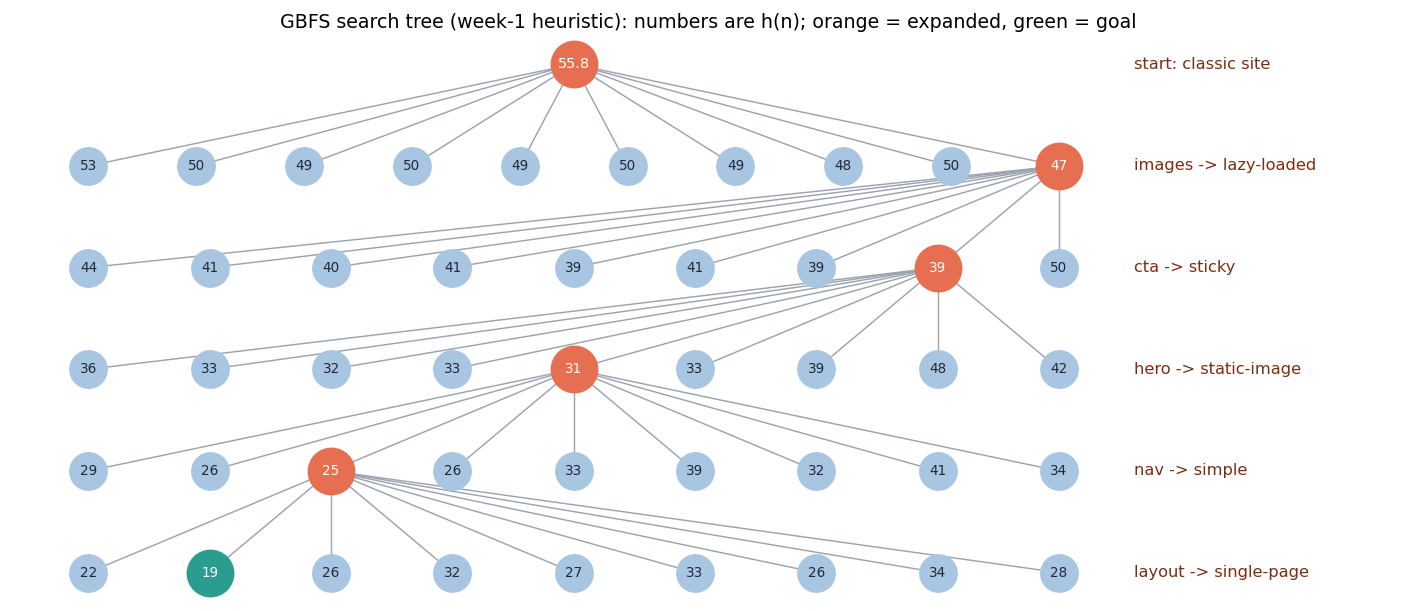

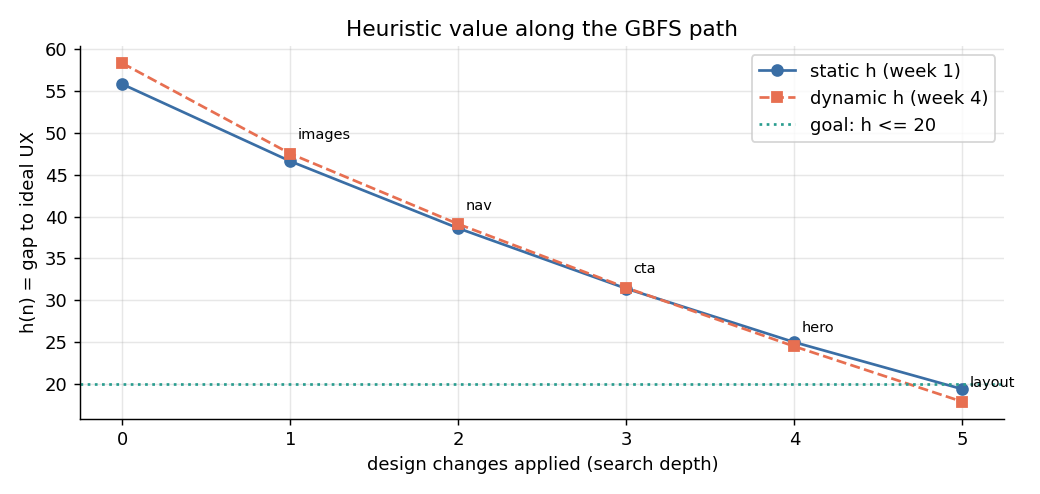

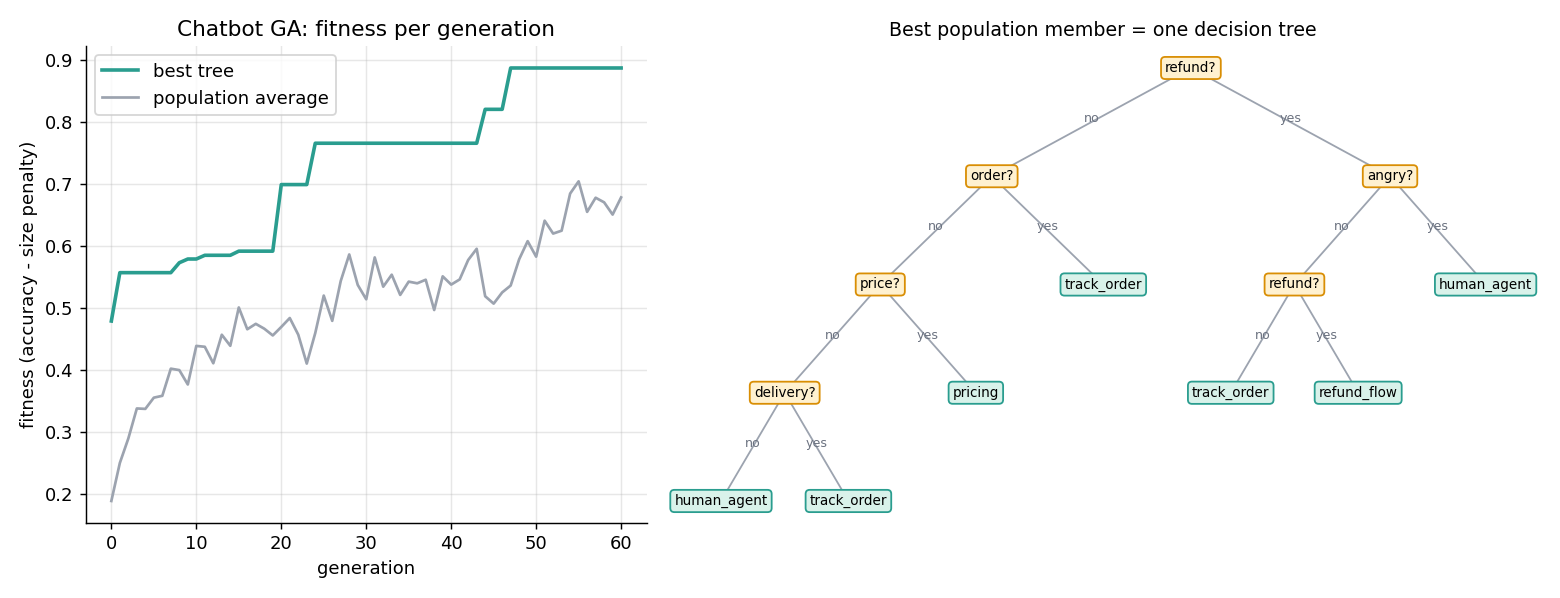

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q01_chart*.png')):
    display(Image(p))